# 08 Local Weighting Synthetic Results

This notebook compares the unweighted, local-only and decision-aware variants for PMMR, KPV and DFPV on the main synthetic benchmark. It reads the article results directory, including appended runs.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").exists():
    for parent in Path.cwd().parents:
        if (parent / "src").exists():
            PROJECT_ROOT = parent
            break
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis.results_analysis import (
    available_metrics,
    export_analysis_tables,
    load_global_curves,
    load_patient_curves,
    load_patient_metadata,
    load_results_metrics,
    make_publication_table,
    metric_spec_available,
    plot_global_curves,
    plot_patient_surface_from_table,
    plot_patient_surface_gallery_from_table,
    run_statistical_tests,
    save_figure,
    set_plot_theme,
    statistical_test_table,
    summarize_metric_ci,
)
from src.analysis.stats import wilcoxon_paired_by_label

set_plot_theme(style="whitegrid", context="notebook", font_scale=1.0)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 260)
pd.set_option("display.expand_frame_repr", False)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.edgecolor"] = "white"

PROJECT_ROOT


WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr')

In [2]:
RESULTS_DIR = PROJECT_ROOT / "results" / "wu2024_article"

SEEDS_TO_ANALYZE = None
if SEEDS_TO_ANALYZE is None:
    SEED_LABEL = "all_seeds"
else:
    SEED_LABEL = f"seeds_{min(SEEDS_TO_ANALYZE)}_{max(SEEDS_TO_ANALYZE)}"

ANALYSIS_DIR = RESULTS_DIR / "analysis" / "08_local_weighting_results" / SEED_LABEL
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

DEFAULT_SPLIT = "test"
ALPHA = 0.05
CONFIDENCE = 0.95
N_BOOT = 3000

METHOD_ORDER = [
    "PMMR",
    "Local PMMR",
    "Weighted PMMR",
    "KPV",
    "Local KPV",
    "Weighted KPV",
    "DFPV",
    "Local DFPV",
    "Weighted DFPV",
]

METHOD_LABELS = {
    "PMMR": "PMMR",
    "Local PMMR": "Local PMMR",
    "Weighted PMMR": "DA-PMMR",
    "KPV": "KPV",
    "Local KPV": "Local KPV",
    "Weighted KPV": "DA-KPV",
    "DFPV": "DFPV",
    "Local DFPV": "Local DFPV",
    "Weighted DFPV": "DA-DFPV",
    "ground_truth_oracle_conditioned": "Ground truth",
    "causal_marginal": "Causal marginal",
    "proxy_conditioned": "Proxy-conditioned",
    "structure_term": "Structure term",
    "ground_truth_causal": r"$E[Y(a)|x]$",
    "associational": r"$E[Y|x,a]$",
    "oracle_conditioned": "Oracle-conditioned",
}

FAMILY_COLORS = {
    "PMMR": "#1f77b4",
    "KPV": "#2ca02c",
    "DFPV": "#d95f02",
}

METHOD_COLORS = {
    "PMMR": FAMILY_COLORS["PMMR"],
    "Local PMMR": FAMILY_COLORS["PMMR"],
    "Weighted PMMR": FAMILY_COLORS["PMMR"],
    "KPV": FAMILY_COLORS["KPV"],
    "Local KPV": FAMILY_COLORS["KPV"],
    "Weighted KPV": FAMILY_COLORS["KPV"],
    "DFPV": FAMILY_COLORS["DFPV"],
    "Local DFPV": FAMILY_COLORS["DFPV"],
    "Weighted DFPV": FAMILY_COLORS["DFPV"],
}

METHOD_LINESTYLES = {
    "PMMR": "-",
    "Local PMMR": "--",
    "Weighted PMMR": ":",
    "KPV": "-",
    "Local KPV": "--",
    "Weighted KPV": ":",
    "DFPV": "-",
    "Local DFPV": "--",
    "Weighted DFPV": ":",
}

METRICS_TO_PLOT = [
    "val_regret",
    "factual_mean_rmse",
    "global_rmse",
    "local_rmse",
    "mean_curve_rmse",
    "mean_curve_argmax_abs_error",
    "regret_causal_marginal",
    "policy_mse_causal_marginal",
    "policy_value_causal_marginal",
]

METRIC_LABELS = {
    "val_regret": "Validation regret",
    "factual_mean_rmse": "Factual RMSE",
    "global_rmse": "Counterfactual RMSE",
    "local_rmse": "Local RMSE",
    "mean_curve_rmse": "Mean curve RMSE",
    "mean_curve_argmax_abs_error": "Argmax absolute error",
    "regret_causal_marginal": "Policy regret",
    "policy_mse_causal_marginal": "Policy MSE",
    "policy_value_causal_marginal": "Policy value",
}

METRIC_DIRECTIONS = {
    "policy_value_causal_marginal": True,
    "policy_value_oracle": True,
    "policy_value_structural": True,
}

RESULTS_DIR, ANALYSIS_DIR


(WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article'),
 WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/08_local_weighting_results/all_seeds'))

In [3]:
VARIANT_ORDER = ["unweighted", "local", "da"]
VARIANT_LABELS = {
    "unweighted": "Unweighted",
    "local": "Local-only",
    "da": "Decision-Aware",
}
VARIANT_HATCHES = {
    "unweighted": None,
    "local": "//",
    "da": "..",
}


def family_of(method_name: str) -> str:
    text = str(method_name)
    if text.startswith("Local "):
        return text[len("Local "):]
    if text.startswith("Weighted "):
        return text[len("Weighted "):]
    return text


def variant_of(method_name: str) -> str:
    text = str(method_name)
    if text.startswith("Local "):
        return "local"
    if text.startswith("Weighted "):
        return "da"
    return "unweighted"


def ordered_existing_methods(values) -> list[str]:
    available = [str(value) for value in values if pd.notna(value)]
    ordered = [method for method in METHOD_ORDER if method in set(available)]
    ordered.extend(sorted(method for method in available if method not in set(ordered)))
    return ordered


def _metric_source_column(metric_name: str) -> tuple[str, str]:
    rows = summary_df.loc[
        summary_df["metric"].astype(str) == str(metric_name),
        ["source_split", "source_metric"],
    ].drop_duplicates()
    if rows.empty:
        raise KeyError(f"Metric {metric_name!r} is not present in summary_df.")
    return str(rows.iloc[0]["source_split"]), str(rows.iloc[0]["source_metric"])


def _bootstrap_ci(values: np.ndarray, *, n_boot: int = N_BOOT, seed: int = 13, alpha: float = 0.05) -> tuple[float, float]:
    arr = np.asarray(values, dtype=float)
    arr = arr[np.isfinite(arr)]
    if arr.size == 0:
        return np.nan, np.nan
    if arr.size == 1:
        return float(arr[0]), float(arr[0])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, arr.size, size=(int(n_boot), arr.size))
    means = arr[idx].mean(axis=1)
    return float(np.quantile(means, alpha / 2.0)), float(np.quantile(means, 1.0 - alpha / 2.0))


def metric_plot_frame(metric_name: str) -> pd.DataFrame:
    split_name, source_metric = _metric_source_column(metric_name)
    frame = metrics_df.copy()
    if "split" in frame.columns:
        frame = frame[frame["split"].astype(str) == split_name]
    frame = frame[frame["method"].isin(METHOD_ORDER)].copy()
    frame["value"] = pd.to_numeric(frame[source_metric], errors="coerce")
    frame = frame[frame["value"].notna()].copy()
    frame["family"] = frame["method"].astype(str).map(family_of)
    frame["variant"] = frame["method"].astype(str).map(variant_of)
    return frame


def plot_family_variant_metric(metric_name: str, *, title: str | None = None, figsize: tuple[float, float] = (8.0, 4.2)) -> plt.Figure:
    frame = metric_plot_frame(metric_name)
    if frame.empty:
        raise ValueError(f"No rows found for metric {metric_name!r}.")

    families = [family for family in ["PMMR", "KPV", "DFPV"] if family in set(frame["family"].astype(str))]
    summary_rows = []
    for family in families:
        for variant in VARIANT_ORDER:
            subset = frame[(frame["family"].astype(str) == family) & (frame["variant"].astype(str) == variant)]
            values = pd.to_numeric(subset["value"], errors="coerce").to_numpy(dtype=float)
            values = values[np.isfinite(values)]
            if values.size == 0:
                continue
            low, high = _bootstrap_ci(values, alpha=1.0 - CONFIDENCE)
            summary_rows.append(
                {
                    "family": family,
                    "variant": variant,
                    "mean": float(np.mean(values)),
                    "ci_low": low,
                    "ci_high": high,
                }
            )
    summary = pd.DataFrame(summary_rows)
    if summary.empty:
        raise ValueError(f"No summary rows found for metric {metric_name!r}.")

    fig, ax = plt.subplots(figsize=figsize)
    centers = np.arange(len(families), dtype=float)
    width = 0.24
    offsets = {"unweighted": -width, "local": 0.0, "da": width}
    for variant in VARIANT_ORDER:
        variant_rows = summary[summary["variant"].astype(str) == variant].copy()
        if variant_rows.empty:
            continue
        x = []
        heights = []
        yerr_low = []
        yerr_high = []
        colors = []
        for family_idx, family in enumerate(families):
            row = variant_rows[variant_rows["family"].astype(str) == family]
            if row.empty:
                continue
            row = row.iloc[0]
            x.append(centers[family_idx] + offsets[variant])
            heights.append(float(row["mean"]))
            yerr_low.append(float(row["mean"]) - float(row["ci_low"]))
            yerr_high.append(float(row["ci_high"]) - float(row["mean"]))
            colors.append(FAMILY_COLORS[family])
        bars = ax.bar(
            x,
            heights,
            width=width,
            yerr=np.vstack([yerr_low, yerr_high]),
            capsize=3,
            color=colors,
            alpha=0.9,
            edgecolor="black",
            linewidth=0.8,
            label=VARIANT_LABELS[variant],
        )
        hatch = VARIANT_HATCHES[variant]
        if hatch:
            for bar in bars:
                bar.set_hatch(hatch)

    ax.set_xticks(centers)
    ax.set_xticklabels(families)
    ax.set_ylabel(METRIC_LABELS.get(metric_name, metric_name))
    if title is not None:
        ax.set_title(title)
    legend_handles = [
        Patch(facecolor="white", edgecolor="black", hatch=VARIANT_HATCHES[variant] or "", label=VARIANT_LABELS[variant])
        for variant in VARIANT_ORDER
    ]
    ax.legend(handles=legend_handles, loc="best", frameon=False)
    fig.tight_layout()
    return fig


def paired_family_tests(metric_name: str, *, correction: str = "holm") -> pd.DataFrame:
    frame = metric_plot_frame(metric_name)
    if frame.empty:
        return pd.DataFrame()
    paired_rows = []
    for family in ["PMMR", "KPV", "DFPV"]:
        subset = frame[frame["family"].astype(str) == family].copy()
        if subset.empty:
            continue
        pivot = subset.pivot_table(
            index=[col for col in ["dataset", "seed", "split"] if col in subset.columns],
            columns="variant",
            values="value",
            aggfunc="first",
        ).reset_index()
        paired = {}
        comparisons = [
            ("local_vs_unweighted", "local", "unweighted"),
            ("da_vs_local", "da", "local"),
            ("da_vs_unweighted", "da", "unweighted"),
        ]
        for label, left, right in comparisons:
            if left not in pivot.columns or right not in pivot.columns:
                continue
            valid = pivot[[left, right]].dropna()
            if valid.empty:
                continue
            paired[label] = (valid[left].to_numpy(dtype=float), valid[right].to_numpy(dtype=float))
        if not paired:
            continue
        result = wilcoxon_paired_by_label(paired, alpha=ALPHA, correction=correction)
        for comparison, row in result.items():
            paired_rows.append(
                {
                    "metric": metric_name,
                    "family": family,
                    "comparison": comparison,
                    **row,
                }
            )
    return pd.DataFrame(paired_rows)


In [4]:
metrics_df = load_results_metrics(RESULTS_DIR)
if SEEDS_TO_ANALYZE is not None:
    seed_set = {int(seed) for seed in SEEDS_TO_ANALYZE}
    metrics_df = metrics_df[metrics_df["seed"].astype("Int64").isin(seed_set)].copy()

global_curves_df = load_global_curves(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)
patient_curves_df = load_patient_curves(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)
patient_metadata_df = load_patient_metadata(RESULTS_DIR, seeds=SEEDS_TO_ANALYZE)

selected_methods = {str(method) for method in METHOD_ORDER}
metrics_df = metrics_df[metrics_df["method"].astype(str).isin(selected_methods)].copy()
global_curves_df = global_curves_df[(global_curves_df["method"].astype(str) == "reference") | (global_curves_df["method"].astype(str).isin(selected_methods))].copy()
patient_curves_df = patient_curves_df[(patient_curves_df["method"].astype(str) == "reference") | (patient_curves_df["method"].astype(str).isin(selected_methods))].copy()

if metrics_df.empty:
    raise ValueError("No local-only synthetic rows were found. Run the local_* models first.")

selected_seeds = sorted(metrics_df["seed"].dropna().astype(int).unique().tolist())
available_test_metrics = available_metrics(metrics_df, split=DEFAULT_SPLIT)
metrics_to_use = [metric for metric in METRICS_TO_PLOT if metric_spec_available(metrics_df, metric, split=DEFAULT_SPLIT)]

print(f"selected seeds: {selected_seeds}")
print(f"analysis_dir: {ANALYSIS_DIR}")
print(f"methods: {ordered_existing_methods(metrics_df['method'].unique())}")
print(f"metrics_to_use: {metrics_to_use}")
display(metrics_df.head())


selected seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
analysis_dir: C:\Users\Alex\CODE\optimal_treatment_proximal_inference\weighted_proximal_oosr\results\wu2024_article\analysis\08_local_weighting_results\all_seeds
methods: ['PMMR', 'Local PMMR', 'Weighted PMMR', 'KPV', 'Local KPV', 'Weighted KPV', 'DFPV', 'Local DFPV', 'Weighted DFPV']
metrics_to_use: ['val_regret', 'factual_mean_rmse', 'global_rmse', 'local_rmse', 'mean_curve_rmse', 'mean_curve_argmax_abs_error', 'regret_causal_marginal', 'policy_mse_causal_marginal', 'policy_value_causal_marginal']


,dataset,seed,split,model_key,method,run_dir,dr_kap_eta,dr_kap_lambda,dr_kap_lambda2,dr_kap_zeta,dr_kpv_lambda1,dr_kpv_lambda2,dr_lambda_dr,dr_pmmr_lambda,factual_mean_mae,factual_mean_rmse,global_rmse,kpv_lambda1,kpv_lambda2,local_rmse,mean_curve_argmax_abs_error,mean_curve_bias,mean_curve_direct_argmax_abs_error,mean_curve_direct_bias,mean_curve_direct_mae,mean_curve_direct_pred_argmax,mean_curve_direct_rmse,mean_curve_direct_true_argmax,mean_curve_mae,mean_curve_pred_argmax,mean_curve_rmse,mean_curve_true_argmax,observed_rmse,optimal_policy_value,optimal_policy_value_causal_marginal,optimal_policy_value_oracle,optimal_policy_value_structural,policy_mse,policy_mse_causal_marginal,policy_mse_oracle,policy_mse_structural,policy_value,policy_value_causal_marginal,policy_value_oracle,policy_value_structural,pseudo_outcome_iqr,pseudo_outcome_std,regret,regret_causal_marginal,regret_oracle,regret_structural,weight_ess_final,raw_method
0,wu2024_nonadditive,0,test,dfpv,DFPV,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.264327,2.854306,7.250690,NaN,NaN,1.535057,1.638807,0.678094,0.595930,-0.699940,4.798768,1.314113,5.580340,0.718183,5.948475,2.356990,6.905607,0.718183,3.595098,0.997879,0.997879,1.163254,1.133451,3.560189,3.560189,3.466197,3.467240,-7.937499,-7.937499,-7.594885,-7.579422,NaN,NaN,8.935378,8.935378,8.758139,8.712873,NaN,DFPV
1,wu2024_nonadditive,0,test,kpv,KPV,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.988493,2.525695,4.226952,0.03,0.001,1.073923,1.638807,1.323591,0.670421,1.243986,3.161422,1.388604,3.946166,0.718183,3.021000,2.356990,3.952257,0.718183,2.752183,0.997879,0.997879,1.163254,1.133451,3.170159,3.170159,3.082504,3.083647,-7.064110,-7.064110,-6.733598,-6.735083,NaN,NaN,8.061989,8.061989,7.896852,7.868534,NaN,KPV
4,wu2024_nonadditive,0,test,pmmr,PMMR,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.337792,2.904998,6.807740,NaN,NaN,1.737543,1.415333,0.650628,1.117368,0.202020,5.401281,1.835552,6.109902,0.718183,5.180792,2.133516,5.950400,0.718183,4.438226,0.997879,0.997879,1.163254,1.133451,2.532052,2.532052,2.394069,2.395911,-5.664955,-5.664955,-5.183292,-5.218365,NaN,NaN,6.662834,6.662834,6.346546,6.351816,NaN,PMMR
7,wu2024_nonadditive,0,test,weighted_pmmr,Weighted PMMR,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.452432,3.067355,6.829273,NaN,NaN,2.156501,1.191860,0.335525,1.042877,0.243798,5.288384,1.761060,5.979989,0.718183,5.204201,1.910043,5.908819,0.718183,4.389237,0.997879,0.997879,1.163254,1.133451,2.288180,2.288180,2.166363,2.168216,-5.153352,-5.153352,-4.682075,-4.731841,NaN,NaN,6.151230,6.151230,5.845329,5.865292,816.114807,Weighted PMMR
8,wu2024_nonadditive,0,validation,dfpv,DFPV,results/wu2024_article/runs/seed_0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.328221,2.971861,7.204308,NaN,NaN,1.467392,1.638807,0.737289,0.670421,-0.847943,4.931131,1.388604,5.756581,0.718183,5.966131,2.356990,6.934634,0.718183,3.700298,1.213106,1.213106,1.176486,1.164157,3.412491,3.412491,3.424752,3.430356,-7.406886,-7.406886,-7.450107,-7.453866,NaN,NaN,8.619993,8.619993,8.626592,8.618024,NaN,DFPV


In [5]:
summary_df = summarize_metric_ci(
    metrics_df,
    metrics_to_use,
    split=DEFAULT_SPLIT,
    confidence=CONFIDENCE,
)
publication_table = make_publication_table(summary_df, metrics=metrics_to_use)

written = export_analysis_tables(
    ANALYSIS_DIR,
    metric_summary=summary_df,
    publication_table=publication_table,
)
display(publication_table.reindex(index=[method for method in METHOD_ORDER if method in publication_table.index]))
written


metric,val_regret,factual_mean_rmse,global_rmse,local_rmse,mean_curve_rmse,mean_curve_argmax_abs_error,regret_causal_marginal,policy_mse_causal_marginal,policy_value_causal_marginal
method,,,,,,,,,
PMMR,"4.946 [3.867, 6.025]","3.005 [2.934, 3.076]","6.861 [6.615, 7.108]","1.454 [1.352, 1.557]","6.144 [5.822, 6.467]","1.023 [0.761, 1.285]","4.922 [3.806, 6.038]","1.764 [1.262, 2.266]","-3.849 [-4.966, -2.732]"
Local PMMR,"4.853 [3.338, 6.369]","3.059 [2.943, 3.176]","6.842 [6.561, 7.123]","1.571 [1.414, 1.728]","6.126 [5.734, 6.518]","1.028 [0.683, 1.373]","4.883 [3.334, 6.431]","1.745 [1.053, 2.437]","-3.777 [-5.321, -2.234]"
Weighted PMMR,"4.377 [3.465, 5.288]","3.213 [3.046, 3.381]","6.719 [6.442, 6.997]","2.003 [1.735, 2.271]","5.937 [5.612, 6.263]","0.919 [0.692, 1.145]","4.317 [3.359, 5.274]","1.493 [1.067, 1.920]","-3.244 [-4.207, -2.280]"
KPV,"4.867 [4.240, 5.493]","2.606 [2.562, 2.649]","4.244 [4.164, 4.323]","0.922 [0.867, 0.978]","4.031 [3.933, 4.128]","1.073 [0.948, 1.197]","4.883 [4.216, 5.551]","1.717 [1.412, 2.022]","-3.810 [-4.492, -3.129]"
Local KPV,"3.845 [3.292, 4.398]","3.097 [2.964, 3.231]","4.093 [3.993, 4.194]","1.200 [1.115, 1.284]","3.819 [3.672, 3.965]","0.864 [0.763, 0.965]","3.860 [3.313, 4.407]","1.244 [1.001, 1.487]","-2.754 [-3.288, -2.221]"
Weighted KPV,"3.302 [2.947, 3.657]","2.823 [2.735, 2.910]","3.969 [3.890, 4.048]","1.123 [1.052, 1.193]","3.635 [3.516, 3.754]","0.745 [0.662, 0.828]","3.311 [2.960, 3.661]","0.999 [0.840, 1.159]","-2.205 [-2.555, -1.855]"
DFPV,"7.524 [6.475, 8.572]","2.908 [2.739, 3.077]","6.738 [6.455, 7.021]","1.866 [1.393, 2.339]","6.421 [6.158, 6.683]","1.495 [1.340, 1.650]","7.631 [6.595, 8.668]","2.976 [2.510, 3.442]","-6.558 [-7.598, -5.518]"
Local DFPV,"6.894 [5.000, 8.787]","3.625 [2.818, 4.433]","6.236 [5.119, 7.353]","3.003 [1.628, 4.378]","5.744 [4.769, 6.718]","1.378 [1.064, 1.692]","6.949 [5.038, 8.860]","2.661 [1.794, 3.528]","-5.843 [-7.761, -3.925]"
Weighted DFPV,"3.493 [2.415, 4.571]","2.784 [2.580, 2.987]","5.301 [4.732, 5.870]","1.551 [1.278, 1.824]","4.861 [4.315, 5.406]","0.760 [0.510, 1.009]","3.501 [2.415, 4.587]","1.106 [0.616, 1.596]","-2.395 [-3.493, -1.298]"


{'metric_summary_ci': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/08_local_weighting_results/all_seeds/metric_summary_ci.csv'),
 'publication_metric_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/08_local_weighting_results/all_seeds/publication_metric_table.csv')}

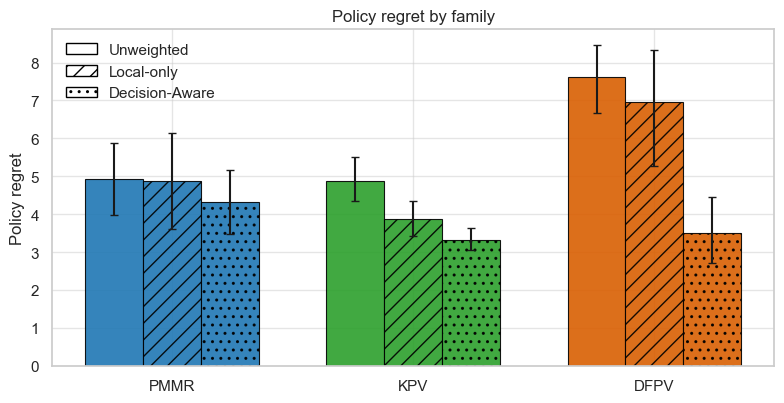

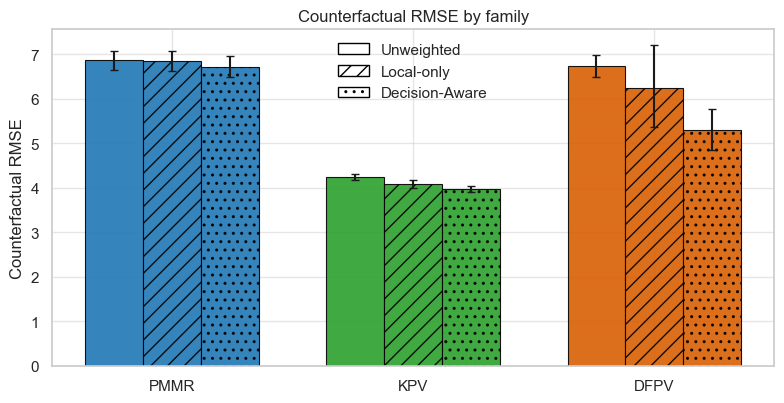

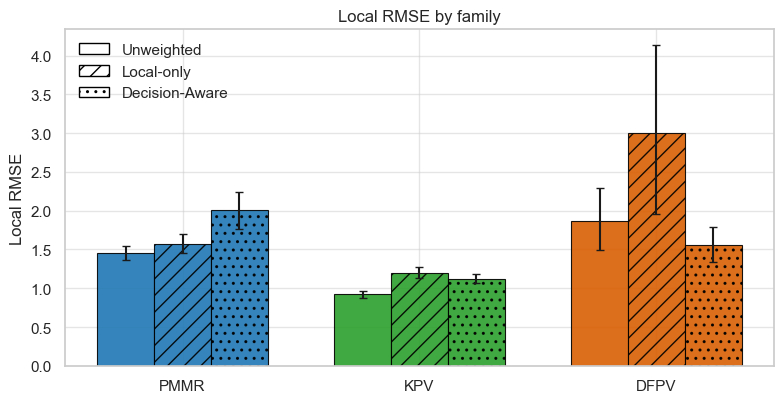

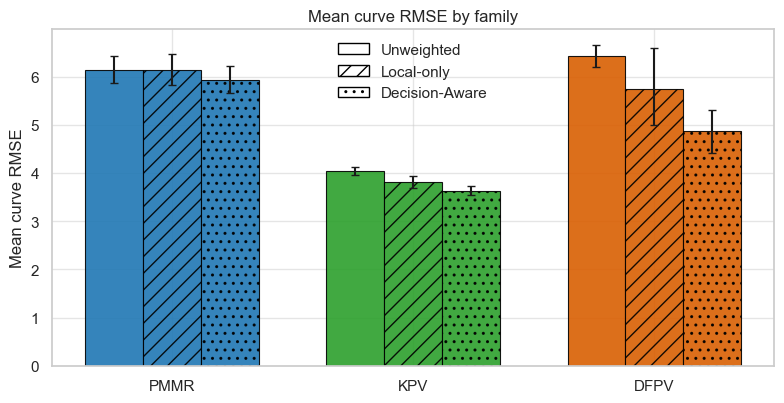

In [6]:
FIGURE_SPECS = [
    ("regret_causal_marginal", "Policy regret by family", "family_policy_regret"),
    ("global_rmse", "Counterfactual RMSE by family", "family_counterfactual_rmse"),
    ("local_rmse", "Local RMSE by family", "family_local_rmse"),
    ("mean_curve_rmse", "Mean curve RMSE by family", "family_mean_curve_rmse"),
]

for metric_name, title, save_stem in FIGURE_SPECS:
    if metric_name not in metrics_to_use:
        print(f"Skipping {metric_name}: metric not present in results.")
        continue
    fig = plot_family_variant_metric(metric_name, title=title)
    save_figure(fig, ANALYSIS_DIR / f"{save_stem}.png")
    save_figure(fig, ANALYSIS_DIR / f"{save_stem}.pdf")
    plt.show()


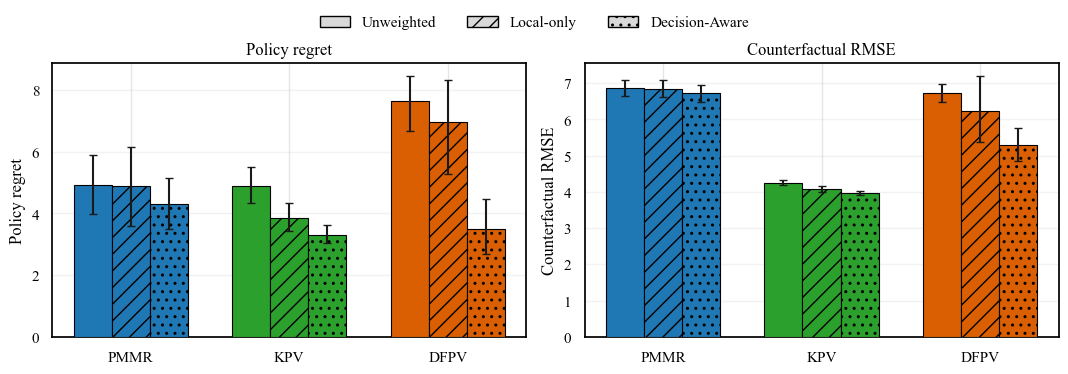

In [11]:
# Paper-style comparison of policy regret and counterfactual RMSE.
COMBINED_METRICS = [
    ('regret_causal_marginal', 'Policy regret'),
    ('global_rmse', 'Counterfactual RMSE'),
]
missing = [name for name, _ in COMBINED_METRICS if name not in metrics_to_use]
if missing:
    raise ValueError(f'Metrics unavailable for the combined figure: {missing}')

paper_style = {
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'font.size': 10.5,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'text.color': 'black',
    'axes.labelcolor': 'black',
    'axes.edgecolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'legend.labelcolor': 'black',
}
with plt.rc_context(paper_style):
    fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.2))
    families = ['PMMR', 'KPV', 'DFPV']
    centers = np.arange(len(families), dtype=float)
    width = 0.24
    offsets = {'unweighted': -width, 'local': 0.0, 'da': width}

    for ax, (metric_name, ylabel) in zip(axes, COMBINED_METRICS):
        frame = metric_plot_frame(metric_name)
        for family_idx, family in enumerate(families):
            for variant in VARIANT_ORDER:
                values = pd.to_numeric(
                    frame.loc[(frame['family'] == family) & (frame['variant'] == variant), 'value'],
                    errors='coerce',
                ).dropna().to_numpy(dtype=float)
                values = values[np.isfinite(values)]
                if not values.size:
                    continue
                mean = float(np.mean(values))
                low, high = _bootstrap_ci(values, n_boot=N_BOOT, alpha=1.0 - CONFIDENCE)
                ax.bar(
                    centers[family_idx] + offsets[variant], mean, width=width,
                    yerr=np.array([[max(0.0, mean - low)], [max(0.0, high - mean)]]),
                    capsize=3, color=FAMILY_COLORS[family], edgecolor='black',
                    linewidth=0.8, hatch=VARIANT_HATCHES[variant] or '', zorder=3,
                )
        ax.set_xticks(centers, families)
        ax.set_title(ylabel)
        ax.set_ylabel(ylabel)
        ax.grid(axis='y', alpha=0.25, zorder=0)
        ax.set_axisbelow(True)

    legend_handles = [
        Patch(facecolor='#d9d9d9', edgecolor='black',
              hatch=VARIANT_HATCHES[variant] or '', label=VARIANT_LABELS[variant])
        for variant in VARIANT_ORDER
    ]
    fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 0.9),
               ncol=len(legend_handles), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.84))
    save_figure(fig, ANALYSIS_DIR / 'family_policy_regret_and_counterfactual_rmse.png')
    save_figure(fig, ANALYSIS_DIR / 'family_policy_regret_and_counterfactual_rmse.pdf')
    plt.show()


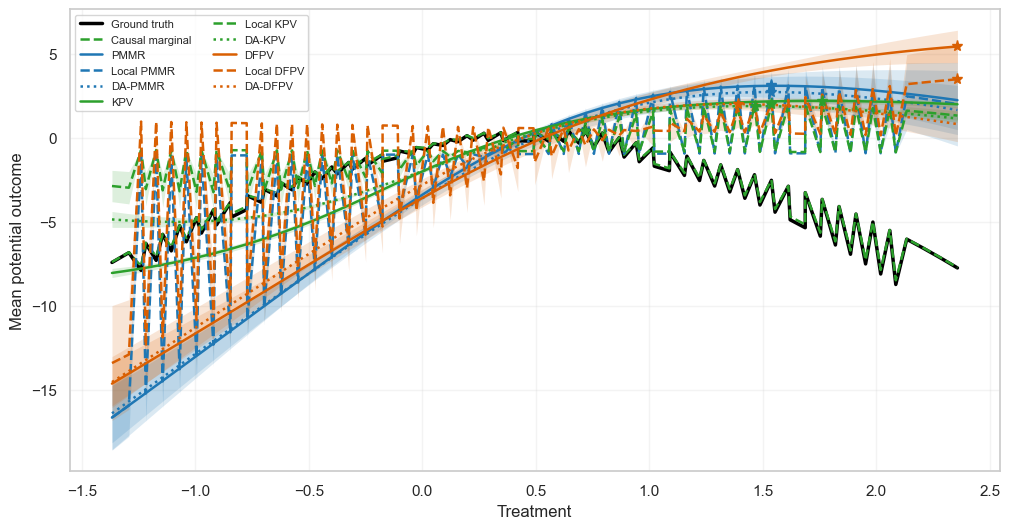

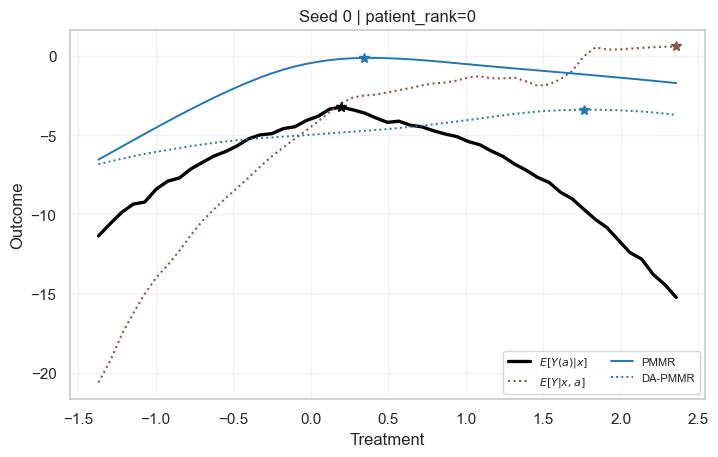

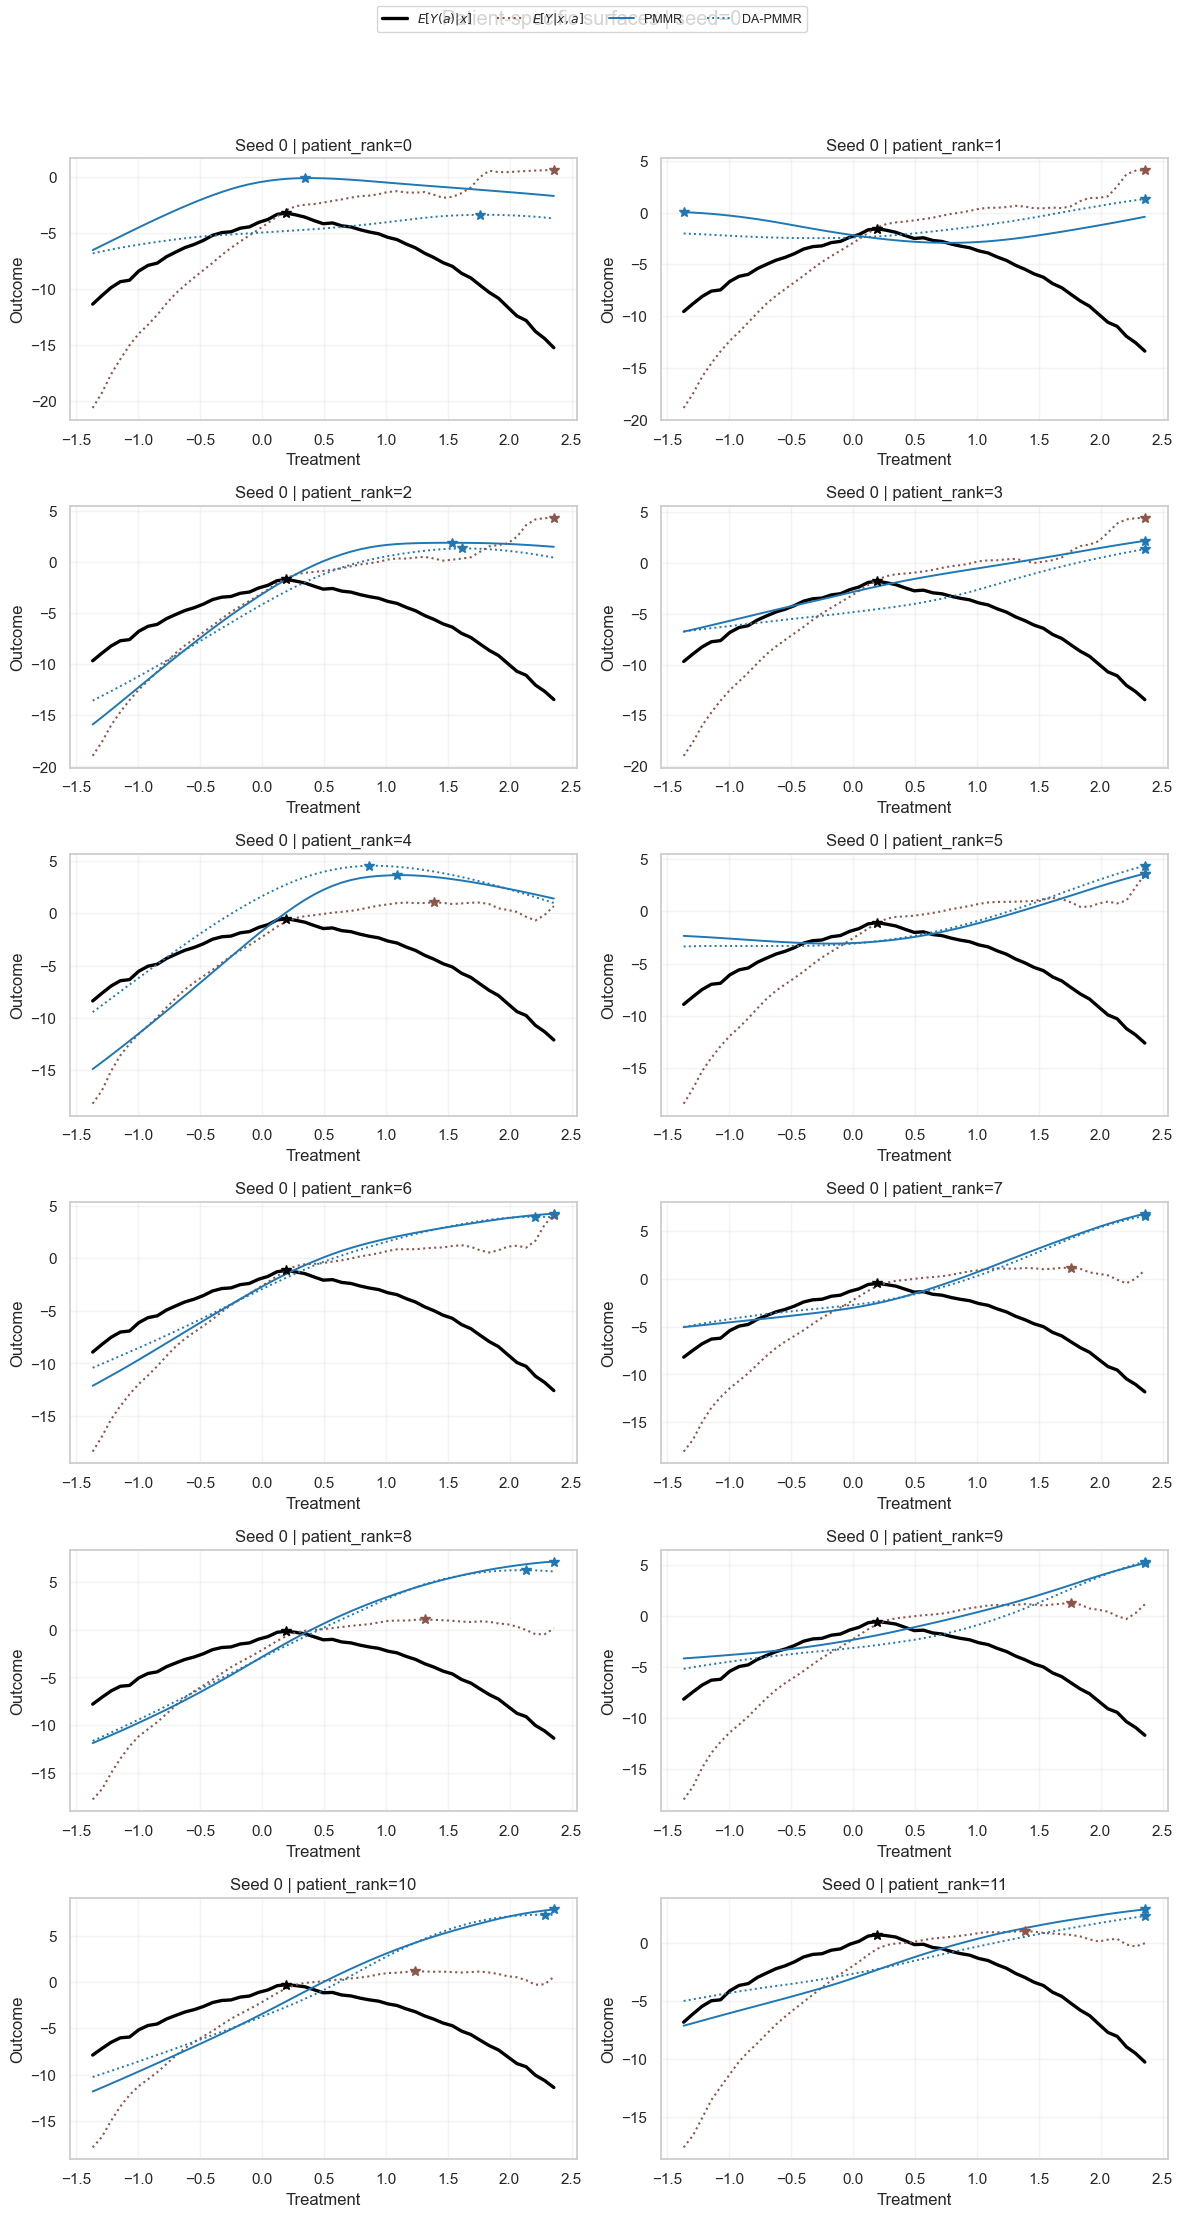

In [8]:
GLOBAL_METHODS = ordered_existing_methods(
    global_curves_df.loc[global_curves_df["curve_type"].astype(str) == "prediction", "method"].dropna().unique()
)
GLOBAL_REFERENCE_VISIBILITY = {
    "ground_truth_oracle_conditioned": True,
    "causal_marginal": True,
    "proxy_conditioned": False,
}

fig = plot_global_curves(
    global_curves_df,
    methods=GLOBAL_METHODS,
    predictor_types=("mean_or_primary",),
    separate_predictor_types=False,
    reference_visibility=GLOBAL_REFERENCE_VISIBILITY,
    mark_curve_maxima=True,
    method_order=METHOD_ORDER,
    labels=METHOD_LABELS,
    colors=METHOD_COLORS,
    linestyles=METHOD_LINESTYLES,
    confidence=CONFIDENCE,
    show_ci=True,
    figsize=(12, 6),
)
save_figure(fig, ANALYSIS_DIR / "global_curves_ci.png")
save_figure(fig, ANALYSIS_DIR / "global_curves_ci.pdf")
plt.show()

prediction_rows = patient_curves_df[
    (patient_curves_df["curve_type"].astype(str) == "prediction")
    & (patient_curves_df["method"].astype(str).isin(METHOD_ORDER))
].copy()
surface_seeds = sorted(prediction_rows["seed"].dropna().astype(int).unique().tolist())
if surface_seeds:
    SURFACE_SEED = int(surface_seeds[0])
    seed_rows = prediction_rows[prediction_rows["seed"].astype(int) == SURFACE_SEED].copy()
    seed_ranks = sorted(seed_rows["patient_rank"].dropna().astype(int).unique().tolist())
    PATIENT_RANK = int(seed_ranks[0])
    SURFACE_METHODS = [method for method in ["PMMR", "Local PMMR", "Weighted PMMR"] if method in set(seed_rows["method"].astype(str))]
    SURFACE_REFERENCE_VISIBILITY = {
        "ground_truth_causal": True,
        "associational": True,
        "proxy_conditioned": False,
        "oracle_conditioned": False,
    }
    fig = plot_patient_surface_from_table(
        patient_curves_df,
        seed=SURFACE_SEED,
        patient_rank=PATIENT_RANK,
        methods=SURFACE_METHODS,
        reference_visibility=SURFACE_REFERENCE_VISIBILITY,
        labels=METHOD_LABELS,
        colors=METHOD_COLORS,
        linestyles=METHOD_LINESTYLES,
        mark_curve_maxima=True,
        figsize=(8.2, 4.8),
    )
    save_figure(fig, ANALYSIS_DIR / f"patient_surface_seed_{SURFACE_SEED}_rank_{PATIENT_RANK}.png")
    save_figure(fig, ANALYSIS_DIR / f"patient_surface_seed_{SURFACE_SEED}_rank_{PATIENT_RANK}.pdf")
    plt.show()

    gallery_ranks = seed_ranks[:12]
    fig = plot_patient_surface_gallery_from_table(
        patient_curves_df,
        seed=SURFACE_SEED,
        patient_ranks=gallery_ranks,
        methods=SURFACE_METHODS,
        reference_visibility=SURFACE_REFERENCE_VISIBILITY,
        labels=METHOD_LABELS,
        colors=METHOD_COLORS,
        linestyles=METHOD_LINESTYLES,
        mark_curve_maxima=True,
        ncols=2,
        figsize_per_panel=(6.0, 3.7),
    )
    save_figure(fig, ANALYSIS_DIR / f"patient_surface_gallery_seed_{SURFACE_SEED}.png")
    save_figure(fig, ANALYSIS_DIR / f"patient_surface_gallery_seed_{SURFACE_SEED}.pdf")
    plt.show()
else:
    print("Skipping patient-surface plots: no prediction rows were found.")


In [9]:
TEST_METHODS = ordered_existing_methods(metrics_df["method"].dropna().unique())
tests = run_statistical_tests(
    metrics_df,
    metrics_to_use,
    split=DEFAULT_SPLIT,
    methods=TEST_METHODS,
    metric_directions=METRIC_DIRECTIONS,
    alpha=ALPHA,
    block_cols=("dataset", "seed"),
)

friedman_posthoc_table = statistical_test_table(tests["friedman_posthoc"], alpha=ALPHA, methods=TEST_METHODS)
wilcoxon_table = statistical_test_table(tests["wilcoxon"], alpha=ALPHA, methods=TEST_METHODS)

display(tests["friedman_omnibus"])
display(friedman_posthoc_table)
display(wilcoxon_table)

export_analysis_tables(
    ANALYSIS_DIR,
    tests=tests,
    test_methods=TEST_METHODS,
)


,metric,n_blocks,n_methods,baseline,higher_is_better,friedman_statistic,friedman_p_value
0,val_regret,10,9,Weighted KPV,False,27.013333,7.032483e-04
1,factual_mean_rmse,10,9,KPV,False,34.506667,3.287625e-05
2,global_rmse,10,9,Weighted KPV,False,62.266667,1.670965e-10
3,local_rmse,10,9,KPV,False,54.320000,5.983940e-09
4,mean_curve_rmse,10,9,Weighted KPV,False,61.866667,2.003124e-10
5,mean_curve_argmax_abs_error,10,9,Weighted KPV,False,24.610581,1.809100e-03
6,regret_causal_marginal,10,9,Weighted KPV,False,26.853333,7.494107e-04
7,policy_mse_causal_marginal,10,9,Weighted KPV,False,28.453333,3.952999e-04
8,policy_value_causal_marginal,10,9,Weighted KPV,True,29.040000,3.120133e-04


method,PMMR,Local PMMR,Weighted PMMR,KPV,Local KPV,Weighted KPV,DFPV,Local DFPV,Weighted DFPV
metric,,,,,,,,,
factual_mean_rmse,0.003,<1e-3,<1e-3,1.000* (baseline),<1e-3,0.200*,0.200*,<1e-3,0.205*
global_rmse,<1e-3,<1e-3,<1e-3,0.574*,1.000*,1.000* (baseline),<1e-3,<1e-3,0.036
local_rmse,0.002,<1e-3,<1e-3,1.000* (baseline),0.259*,0.383*,<1e-3,<1e-3,<1e-3
mean_curve_argmax_abs_error,0.300*,0.890*,1.000*,0.236*,1.000*,1.000* (baseline),0.003,0.006,1.000*
mean_curve_rmse,<1e-3,<1e-3,<1e-3,0.574*,1.000*,1.000* (baseline),<1e-3,<1e-3,0.057*
policy_mse_causal_marginal,0.080*,0.432*,0.883*,0.300*,1.000*,1.000* (baseline),0.002,0.002,1.000*
policy_value_causal_marginal,0.080*,0.604*,0.660*,0.247*,0.982*,1.000* (baseline),0.001,0.003,1.000*
regret_causal_marginal,0.192*,0.604*,1.000*,0.300*,1.000*,1.000* (baseline),0.002,0.003,1.000*
val_regret,0.156*,0.512*,1.000*,0.247*,1.000*,1.000* (baseline),0.002,0.005,1.000*


method,PMMR,Local PMMR,Weighted PMMR,KPV,Local KPV,Weighted KPV,DFPV,Local DFPV,Weighted DFPV
metric,,,,,,,,,
factual_mean_rmse,0.009,0.009,0.009,1.000* (baseline),0.009,0.009,0.015,0.012,0.049
global_rmse,0.009,0.009,0.009,0.009,0.027,1.000* (baseline),0.009,0.009,0.009
local_rmse,0.009,0.009,0.009,1.000* (baseline),0.009,0.009,0.009,0.009,0.009
mean_curve_argmax_abs_error,0.164*,0.200*,0.203*,0.009,0.203*,1.000* (baseline),0.016,0.016,1.000*
mean_curve_rmse,0.009,0.009,0.009,0.009,0.027,1.000* (baseline),0.009,0.009,0.009
policy_mse_causal_marginal,0.059*,0.161*,0.168*,0.009,0.168*,1.000* (baseline),0.009,0.034,0.846*
policy_value_causal_marginal,0.082*,0.161*,0.168*,0.009,0.168*,1.000* (baseline),0.009,0.034,0.846*
regret_causal_marginal,0.111*,0.161*,0.168*,0.009,0.168*,1.000* (baseline),0.009,0.034,0.846*
val_regret,0.082*,0.161*,0.161*,0.009,0.161*,1.000* (baseline),0.009,0.034,0.846*


{'friedman_omnibus': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/08_local_weighting_results/all_seeds/friedman_omnibus.csv'),
 'friedman_posthoc': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/08_local_weighting_results/all_seeds/friedman_posthoc.csv'),
 'wilcoxon': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/08_local_weighting_results/all_seeds/wilcoxon.csv'),
 'friedman_posthoc_holm_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/08_local_weighting_results/all_seeds/friedman_posthoc_holm_table.csv'),
 'wilcoxon_holm_table': WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/wu2024_article/analysis/08_local_weighting_res

In [10]:
WITHIN_FAMILY_METRICS = [metric for metric in ["regret_causal_marginal", "global_rmse", "local_rmse", "mean_curve_rmse"] if metric in metrics_to_use]
paired_frames = [paired_family_tests(metric_name, correction="holm") for metric_name in WITHIN_FAMILY_METRICS]
paired_frames = [frame for frame in paired_frames if not frame.empty]
within_family_df = pd.concat(paired_frames, ignore_index=True) if paired_frames else pd.DataFrame()
if not within_family_df.empty:
    within_family_df = within_family_df.sort_values(["metric", "family", "comparison"]).reset_index(drop=True)
    within_family_path = ANALYSIS_DIR / "within_family_wilcoxon_holm.csv"
    within_family_df.to_csv(within_family_path, index=False)
    display(within_family_df)
    print(within_family_path)
else:
    print("No within-family paired Wilcoxon rows were produced.")


,metric,family,comparison,label,n_pairs,wilcoxon_statistic,p_value_uncorrected,p_value,rejected,correction,alternative
0,global_rmse,DFPV,da_vs_local,da_vs_local,10,12.0,0.130859,0.261719,False,holm,two-sided
1,global_rmse,DFPV,da_vs_unweighted,da_vs_unweighted,10,1.0,0.003906,0.011719,True,holm,two-sided
2,global_rmse,DFPV,local_vs_unweighted,local_vs_unweighted,10,19.0,0.431641,0.431641,False,holm,two-sided
3,global_rmse,KPV,da_vs_local,da_vs_local,10,6.0,0.027344,0.054688,False,holm,two-sided
4,global_rmse,KPV,da_vs_unweighted,da_vs_unweighted,10,0.0,0.001953,0.005859,True,holm,two-sided
5,global_rmse,KPV,local_vs_unweighted,local_vs_unweighted,10,9.0,0.064453,0.064453,False,holm,two-sided
6,global_rmse,PMMR,da_vs_local,da_vs_local,10,16.0,0.275391,0.550781,False,holm,two-sided
7,global_rmse,PMMR,da_vs_unweighted,da_vs_unweighted,15,35.0,0.168823,0.506470,False,holm,two-sided
8,global_rmse,PMMR,local_vs_unweighted,local_vs_unweighted,10,16.0,0.275391,0.550781,False,holm,two-sided
9,local_rmse,DFPV,da_vs_local,da_vs_local,10,6.0,0.027344,0.082031,False,holm,two-sided


C:\Users\Alex\CODE\optimal_treatment_proximal_inference\weighted_proximal_oosr\results\wu2024_article\analysis\08_local_weighting_results\all_seeds\within_family_wilcoxon_holm.csv


| Model | Comparison | Adjusted p-value | Significant? |
|-------|------------|-----------------:|:------------:|
| DFPV  | Decision-Aware vs. Local | 0.005859 | ﷿﷿﷿ |
| KPV   | Decision-Aware vs. Local | 0.167969 | ﷿﷿﷿ |
| PMMR  | Decision-Aware vs. Local | 0.320312 | ﷿﷿﷿ |

| Violation | DFPV | Weighted DFPV | KPV | Weighted KPV | PMMR | Weighted PMMR |
|:---------:|-----:|--------------:|----:|-------------:|-----:|--------------:|
| 0.00 | 5.83 ﷿﷿ 2.49 | **3.25 ﷿﷿ 1.24** | 4.29 ﷿﷿ 0.33 | **3.30 ﷿﷿ 0.44** | 5.02 ﷿﷿ 1.89 | **4.28 ﷿﷿ 1.69** |
| 0.25 | 7.41 ﷿﷿ 2.07 | **3.18 ﷿﷿ 1.95** | 4.33 ﷿﷿ 0.37 | **3.32 ﷿﷿ 0.45** | 5.19 ﷿﷿ 1.91 | **4.54 ﷿﷿ 1.66** |
| 0.50 | 8.83 ﷿﷿ 0.06 | **4.75 ﷿﷿ 2.99** | 4.53 ﷿﷿ 0.48 | **3.79 ﷿﷿ 0.86** | 6.25 ﷿﷿ 1.85 | **5.55 ﷿﷿ 1.98** |
| 0.75 | 8.26 ﷿﷿ 0.83 | **5.11 ﷿﷿ 2.10** | 5.11 ﷿﷿ 0.66 | **4.44 ﷿﷿ 1.27** | 7.46 ﷿﷿ 1.39 | **6.99 ﷿﷿ 1.81** |
| 0.90 | 7.89 ﷿﷿ 1.03 | **5.73 ﷿﷿ 2.42** | 5.87 ﷿﷿ 1.11 | **4.89 ﷿﷿ 1.65** | 7.94 ﷿﷿ 0.84 | **7.67 ﷿﷿ 1.03** |